# Pipeline complet — Régression : échantillons d'apprentissage / validation / test
Même logique que `02_Reg_pipeline_complet.ipynb`, mais **sans validation croisée** : les données sont découpées **une seule fois** en trois échantillons.

| Échantillon | Rôle |
|---|---|
| **Apprentissage** | ajuste les modèles |
| **Validation** | choisit les hyperparamètres (λ, nombre de composantes, nombre d'itérations du boosting) et sert d'échantillon d'early stopping |
| **Test** | évalue **une seule fois** le modèle final : c'est l'estimation honnête de l'erreur de généralisation |

**Modèles comparés** : `MCO`, `BIC` / `AIC` (sélection pas à pas, sur l'apprentissage), `lasso`, `elastic`, `ridge`, `pcr`, `pls`, `foret`, `gbm1`, `gbm2`, `gbms1`, `gbms2`, `cat`.

**Étapes** : 1. configuration → 2. données et découpage → 3. ajustement de tous les modèles → 4. résultats (tableau avec intervalles de confiance, graphiques, hyperparamètres choisis, courbes de validation) → 5. export.

> **Précautions** : avec un seul découpage, les résultats dépendent du tirage (changer `GRAINE_SPLIT` pour s'en rendre compte) et l'échantillon de test est petit. Les intervalles de confiance du tableau (bootstrap des erreurs de test) donnent l'ordre de grandeur de l'incertitude : des méthodes dont les IC se recouvrent ne sont pas réellement départageables. Le MSE de validation est **optimiste** (il a servi à choisir les réglages) : c'est le MSE de test qui fait foi.

## 1. Configuration

In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from patsy import dmatrix

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore")

try:
    from catboost import CatBoostRegressor
except ImportError:
    CatBoostRegressor = None
    print("catboost non installé (pip install catboost) : la méthode 'cat' sera ignorée")

try:
    import ols_step_sk
except ImportError:
    ols_step_sk = None
    print("ols_step_sk.py introuvable : BIC et AIC seront ignorés")

# ← Paramètres à modifier
URL_DONNEES = "https://regression-avec-python.github.io/donnees/ozone_transf.txt"
NOM_Y = "maxO3"          # variable à prédire (renommée Y)
ESPACE = "X"             # espace des variables : "X" (base), "XI" (interactions), "XP" (polynômes 2-3), "XIP" (les deux)
TAILLE_TEST = 0.2        # part de l'échantillon de test
TAILLE_VAL = 0.2         # part de l'échantillon de validation (le reste = apprentissage)
GRAINE_SPLIT = 1234      # graine du découpage apprentissage / validation / test
GRAINE = 42              # graine de tous les modèles (résultats reproductibles)
CALCULER_IC = True       # BIC / AIC : rapide avec "X", très long avec XI / XIP
N_BOOT_IC = 1000         # rééchantillonnages pour les intervalles de confiance du MSE de test
DOSSIER_SORTIE = "./"    # dossier où écrire les fichiers résultats

# Option pour tester le code rapidement : n'utilise qu'une fraction des lignes, tirées au hasard.
# Les résultats n'ont alors aucune valeur ; les fichiers sont écrits dans test_pipeline/ pour ne rien écraser.
MODE_TEST = False        # True pour activer le mode test
FRACTION_TEST = 0.10     # part des lignes conservées en mode test
GRAINE_ECHANTILLON = 2025   # graine du tirage des lignes
if MODE_TEST:
    DOSSIER_SORTIE = "test_pipeline/"
    os.makedirs(DOSSIER_SORTIE, exist_ok=True)
    print(f"MODE TEST : {FRACTION_TEST:.0%} des lignes, résultats écrits dans {DOSSIER_SORTIE}")

## 2. Données et découpage

In [2]:
don = pd.read_csv(URL_DONNEES, header=0, sep=";", index_col=0)
don.rename(columns={NOM_Y: "Y"}, inplace=True)
if MODE_TEST:
    don = don.sample(frac=FRACTION_TEST, random_state=GRAINE_ECHANTILLON).sort_index()

nomsvar = list(don.columns.difference(["Y"]))
X_base = np.asarray(dmatrix("~" + "+".join(nomsvar), don))[:, 1:]      # variables qualitatives codées par patsy
espaces = {"X": X_base}
if ESPACE in ("XI", "XIP"):
    XI = np.asarray(dmatrix("1 + (" + "+".join(nomsvar) + ")**2", don))[:, 1:]    # interactions deux à deux
    espaces["XI"] = XI
if ESPACE in ("XP", "XIP"):
    XP = np.concatenate((X_base, X_base**2, X_base**3), axis=1)                  # polynômes degrés 2 et 3
    espaces["XP"] = XP
if ESPACE == "XIP":
    espaces["XIP"] = np.concatenate((XI, XP), axis=1)

X = espaces[ESPACE]
Y = don["Y"].to_numpy()

idx = np.arange(len(Y))
idx_appval, idx_test = train_test_split(idx, test_size=TAILLE_TEST, random_state=GRAINE_SPLIT)
idx_app, idx_val = train_test_split(idx_appval, test_size=TAILLE_VAL / (1 - TAILLE_TEST), random_state=GRAINE_SPLIT)

X_app, X_val, X_test = X[idx_app], X[idx_val], X[idx_test]
Y_app, Y_val, Y_test = Y[idx_app], Y[idx_val], Y[idx_test]
print(f"Espace {ESPACE} : {X.shape[1]} variables")
print(f"Apprentissage : {len(idx_app)} obs | Validation : {len(idx_val)} obs | Test : {len(idx_test)} obs")

Espace X : 21 variables
Apprentissage : 819 obs | Validation : 273 obs | Test : 274 obs


## 3. Ajustement de tous les modèles
Pour chaque méthode, on ajuste sur l'**apprentissage**, on règle les hyperparamètres sur la **validation**, puis on prédit validation et test. Aucun modèle ne voit l'échantillon de test avant la prédiction finale.

In [3]:
pred_val, pred_test = {}, {}      # prédictions par méthode
hyper = {}                        # hyperparamètres retenus
temps = {}                        # temps de calcul par méthode (s)
courbes = {}                      # courbes d'erreur de validation (pour les graphiques)


def enregistrer(nom, pv, pt, t0, **params):
    pred_val[nom], pred_test[nom] = np.ravel(pv), np.ravel(pt)
    temps[nom] = time.time() - t0
    hyper.update(params)


def mse(y, p):
    return mean_squared_error(y, np.ravel(p))


# --- MCO
t0 = time.time()
mco = LinearRegression().fit(X_app, Y_app)
enregistrer("MCO", mco.predict(X_val), mco.predict(X_test), t0)

# --- BIC / AIC : la sélection de variables se fait sur l'apprentissage (critère d'information, pas de validation)
if CALCULER_IC and ols_step_sk is not None:
    for crit in ("bic", "aic"):
        t0 = time.time()
        sel = ols_step_sk.LinearRegressionSelectionFeatureIC(verbose=0, crit=crit)
        if not hasattr(sel, "tol"):         # compatibilité avec les versions récentes de scikit-learn
            sel.tol = 1e-6
        sel.fit(X=X_app, y=Y_app)
        enregistrer(crit.upper(), sel.predict(X_val), sel.predict(X_test), t0,
                    **{f"nb_var_{crit.upper()}": len(sel.selected_features_)})

# --- Lasso, ElasticNet, Ridge : variables centrées-réduites sur l'apprentissage, paramètre choisi sur la validation
cr = StandardScaler().fit(X_app)
Z_app, Z_val, Z_test = cr.transform(X_app), cr.transform(X_val), cr.transform(X_test)
alpha_max = np.abs(Z_app.T.dot(Y_app - Y_app.mean())).max() / len(Y_app)     # plus petit alpha qui annule tous les coefficients


def choisir_penalisation(nom, fabrique, grille_alpha):
    t0 = time.time()
    erreurs = [mse(Y_val, fabrique(a).fit(Z_app, Y_app).predict(Z_val)) for a in grille_alpha]
    meilleur = grille_alpha[int(np.argmin(erreurs))]
    modele = fabrique(meilleur).fit(Z_app, Y_app)
    courbes[nom] = (grille_alpha, np.array(erreurs))
    enregistrer(nom, modele.predict(Z_val), modele.predict(Z_test), t0, **{f"alpha_{nom}": meilleur})


choisir_penalisation("lasso", lambda a: Lasso(alpha=a, max_iter=10000, random_state=GRAINE),
                     alpha_max * np.logspace(0, -4, 100))
choisir_penalisation("elastic", lambda a: ElasticNet(alpha=a, l1_ratio=0.5, max_iter=10000, random_state=GRAINE),
                     alpha_max / 0.5 * np.logspace(0, -4, 100))
choisir_penalisation("ridge", lambda a: Ridge(alpha=a, random_state=GRAINE), np.logspace(-4, 5, 100))

# --- PCR (ACP puis MCO) et PLS : nombre de composantes choisi sur la validation
nmax = X.shape[1]
for nom, fabrique in [
    ("pcr", lambda k: Pipeline([("cr", StandardScaler()), ("acp", PCA(n_components=k, random_state=GRAINE)),
                                ("reg", LinearRegression())])),
    ("pls", lambda k: PLSRegression(n_components=k)),
]:
    t0 = time.time()
    ks = np.arange(1, nmax + 1)
    erreurs = [mse(Y_val, fabrique(k).fit(X_app, Y_app).predict(X_val)) for k in ks]
    k_opt = int(ks[int(np.argmin(erreurs))])
    modele = fabrique(k_opt).fit(X_app, Y_app)
    enregistrer(nom, modele.predict(X_val), modele.predict(X_test), t0, **{f"nb_comp_{nom}": k_opt})

# --- Forêt aléatoire
t0 = time.time()
foret = RandomForestRegressor(random_state=GRAINE).fit(X_app, Y_app)
enregistrer("foret", foret.predict(X_val), foret.predict(X_test), t0)

# --- Gradient boosting et stochastic gradient boosting : le nombre d'itérations minimise l'erreur de validation
configs_gbm = {
    "gbm1":  dict(n_estimators=1000, max_depth=1, learning_rate=0.1),
    "gbm2":  dict(n_estimators=1000, max_depth=2, learning_rate=0.1),
    "gbms1": dict(n_estimators=5000, max_depth=1, learning_rate=0.1, subsample=0.2),
    "gbms2": dict(n_estimators=5000, max_depth=2, learning_rate=0.1, subsample=0.2),
}
for nom, params in configs_gbm.items():
    t0 = time.time()
    gbm = GradientBoostingRegressor(**params, random_state=GRAINE).fit(X_app, Y_app)
    stages_val = list(gbm.staged_predict(X_val))
    stages_test = list(gbm.staged_predict(X_test))
    erreurs = np.array([mse(Y_val, p) for p in stages_val])
    k = int(np.argmin(erreurs))
    courbes[nom] = (np.arange(1, len(erreurs) + 1), erreurs)
    enregistrer(nom, stages_val[k], stages_test[k], t0, **{f"nb_iter_{nom}": k + 1})

# --- CatBoost : early stopping sur l'échantillon de validation
if CatBoostRegressor is not None:
    t0 = time.time()
    cat = CatBoostRegressor(iterations=5000, learning_rate=0.1, subsample=0.1, loss_function="RMSE",
                            random_seed=GRAINE, verbose=0, allow_writing_files=False)
    cat.fit(X_app, Y_app, eval_set=(X_val, Y_val), early_stopping_rounds=10)
    enregistrer("cat", cat.predict(X_val), cat.predict(X_test), t0, nb_iter_cat=cat.get_best_iteration())

methodes = list(pred_test)
print(f"{len(methodes)} méthodes ajustées -> {methodes}")

14 méthodes ajustées -> ['MCO', 'BIC', 'AIC', 'lasso', 'elastic', 'ridge', 'pcr', 'pls', 'foret', 'gbm1', 'gbm2', 'gbms1', 'gbms2', 'cat']


## 4. Résultats
### 4.1 Tableau des performances
- **MSE_test** : critère de classement (estimation honnête) ; **IC95** : intervalle de confiance bootstrap
- **MSE_val** : erreur sur l'échantillon qui a servi à régler les modèles (optimiste)
- **RMSE**, **MAE**, **R2** : calculés sur le test ; **Gain_vs_MCO_%** : variation relative du MSE de test par rapport aux MCO

In [4]:
famille = {"MCO": "Moindres carrés", "BIC": "Moindres carrés", "AIC": "Moindres carrés",
           "lasso": "Pénalisation", "elastic": "Pénalisation", "ridge": "Pénalisation",
           "pcr": "Réduction de dim.", "pls": "Réduction de dim.", "foret": "Forêt aléatoire",
           "gbm1": "Boosting", "gbm2": "Boosting", "gbms1": "Boosting", "gbms2": "Boosting", "cat": "Boosting"}

rng_ic = np.random.default_rng(GRAINE)
tirages = rng_ic.integers(0, len(Y_test), size=(N_BOOT_IC, len(Y_test)))      # mêmes rééchantillonnages pour toutes les méthodes

res_test = pd.DataFrame({m: pred_test[m] - Y_test for m in methodes})           # résidu = prédit - observé
res_val = pd.DataFrame({m: pred_val[m] - Y_val for m in methodes})

metriques = pd.DataFrame(index=methodes)
metriques["Famille"] = [famille[m] for m in methodes]
metriques["MSE_test"] = (res_test ** 2).mean()
mse_boot = np.array([(res_test[m].to_numpy()[tirages] ** 2).mean(axis=1) for m in methodes])
metriques["IC95_bas"] = np.quantile(mse_boot, 0.025, axis=1)
metriques["IC95_haut"] = np.quantile(mse_boot, 0.975, axis=1)
metriques["MSE_val"] = (res_val ** 2).mean()
metriques["RMSE_test"] = np.sqrt(metriques["MSE_test"])
metriques["MAE_test"] = res_test.abs().mean()
metriques["R2_test"] = 1 - metriques["MSE_test"] / Y_test.var()
metriques["Gain_vs_MCO_%"] = 100 * (metriques["MSE_test"] / metriques.loc["MCO", "MSE_test"] - 1)
metriques["Temps_s"] = pd.Series(temps)
metriques = metriques.sort_values("MSE_test")
metriques.insert(1, "Rang", range(1, len(metriques) + 1))

metriques.round(3)

,Famille,Rang,MSE_test,IC95_bas,IC95_haut,MSE_val,RMSE_test,MAE_test,R2_test,Gain_vs_MCO_%,Temps_s
gbm2,Boosting,1,147.173,120.493,177.761,165.688,12.132,9.353,0.762,-17.766,6.394
gbms1,Boosting,2,150.383,123.954,180.825,168.786,12.263,9.507,0.756,-15.973,14.775
gbm1,Boosting,3,151.806,124.381,180.489,163.975,12.321,9.579,0.754,-15.178,4.221
gbms2,Boosting,4,152.849,124.035,183.307,158.557,12.363,9.397,0.752,-14.595,8.666
foret,Forêt aléatoire,5,155.759,124.769,187.311,174.060,12.480,9.439,0.748,-12.969,1.566
cat,Boosting,6,156.297,125.556,189.335,161.479,12.502,9.387,0.747,-12.669,0.246
BIC,Moindres carrés,7,176.811,143.374,214.908,173.910,13.297,10.460,0.714,-1.206,0.615
AIC,Moindres carrés,8,177.165,144.380,216.015,173.597,13.310,10.347,0.713,-1.009,0.596
lasso,Pénalisation,9,178.022,144.199,217.657,171.897,13.342,10.350,0.712,-0.530,0.518
elastic,Pénalisation,10,178.802,144.692,217.827,172.171,13.372,10.366,0.710,-0.094,0.516


### 4.2 Graphiques : MSE validation vs test et résidus de test

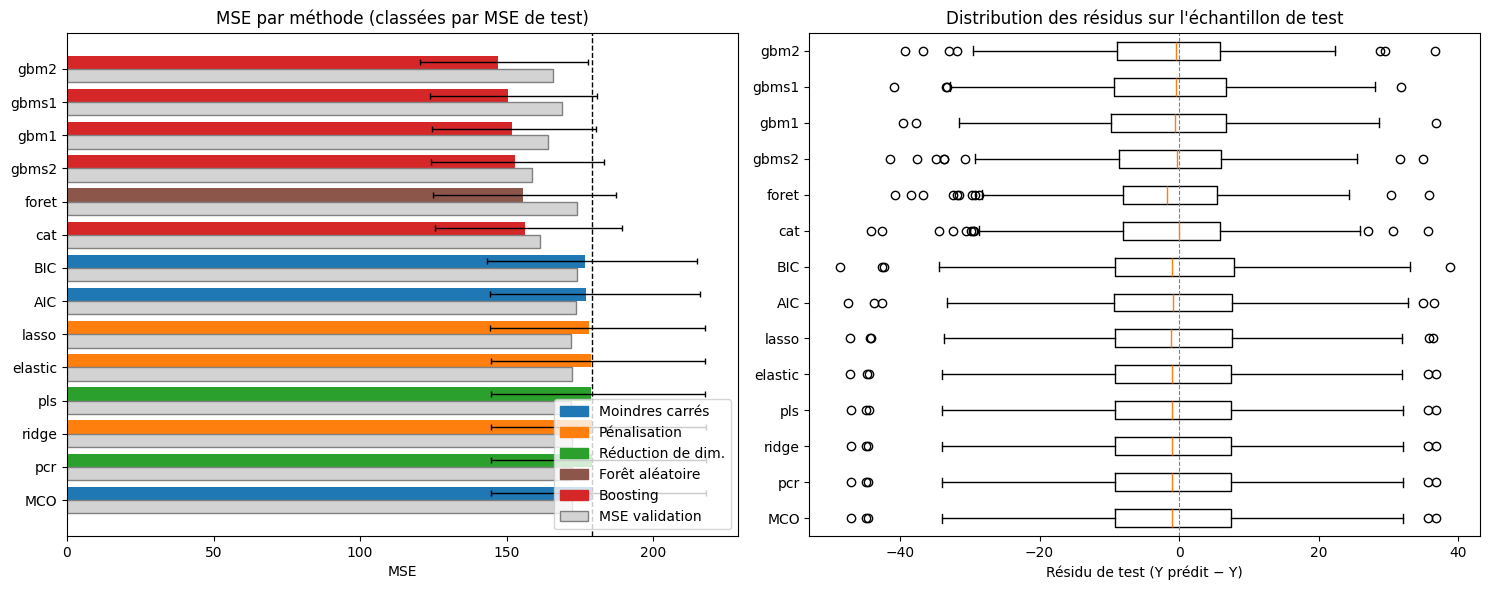

In [5]:
couleurs_famille = {"Moindres carrés": "tab:blue", "Pénalisation": "tab:orange", "Réduction de dim.": "tab:green",
                    "Forêt aléatoire": "tab:brown", "Boosting": "tab:red"}
ordre = metriques.index.tolist()
pos = np.arange(len(ordre))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

ax1.barh(pos - 0.2, metriques["MSE_test"], height=0.4, color=[couleurs_famille[f] for f in metriques["Famille"]],
         xerr=[metriques["MSE_test"] - metriques["IC95_bas"], metriques["IC95_haut"] - metriques["MSE_test"]],
         error_kw=dict(ecolor="black", capsize=2, lw=1), label="MSE test (± IC95)")
ax1.barh(pos + 0.2, metriques["MSE_val"], height=0.4, color="lightgrey", edgecolor="grey", label="MSE validation")
ax1.set_yticks(pos)
ax1.set_yticklabels(ordre)
ax1.invert_yaxis()
ax1.axvline(metriques.loc["MCO", "MSE_test"], color="black", linestyle="--", linewidth=1)
ax1.set_xlabel("MSE")
ax1.set_title("MSE par méthode (classées par MSE de test)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in couleurs_famille.values()]
handles.append(plt.Rectangle((0, 0), 1, 1, color="lightgrey", ec="grey"))
ax1.legend(handles, list(couleurs_famille) + ["MSE validation"], loc="lower right")

ax2.boxplot([res_test[m].values for m in ordre], tick_labels=ordre, vert=False)
ax2.invert_yaxis()
ax2.axvline(0, color="grey", linestyle="--", linewidth=0.8)
ax2.set_xlabel("Résidu de test (Y prédit − Y)")
ax2.set_title("Distribution des résidus sur l'échantillon de test")

plt.tight_layout()
plt.savefig(DOSSIER_SORTIE + "resultats_reg_split_mse_residus.png", dpi=150)
plt.show()

### 4.3 Hyperparamètres choisis et courbes de validation
Les courbes montrent l'erreur de **validation** en fonction du réglage : le minimum (point rouge) est le réglage retenu. Un minimum plat signifie que le réglage compte peu ; un minimum au bord de la grille signale qu'il faudrait élargir la grille.

,valeur retenue
nb_var_BIC,5.0000
nb_var_AIC,9.0000
alpha_lasso,0.0395
alpha_elastic,0.0030
alpha_ridge,0.0001
nb_comp_pcr,21.0000
nb_comp_pls,15.0000
nb_iter_gbm1,180.0000
nb_iter_gbm2,74.0000
nb_iter_gbms1,130.0000


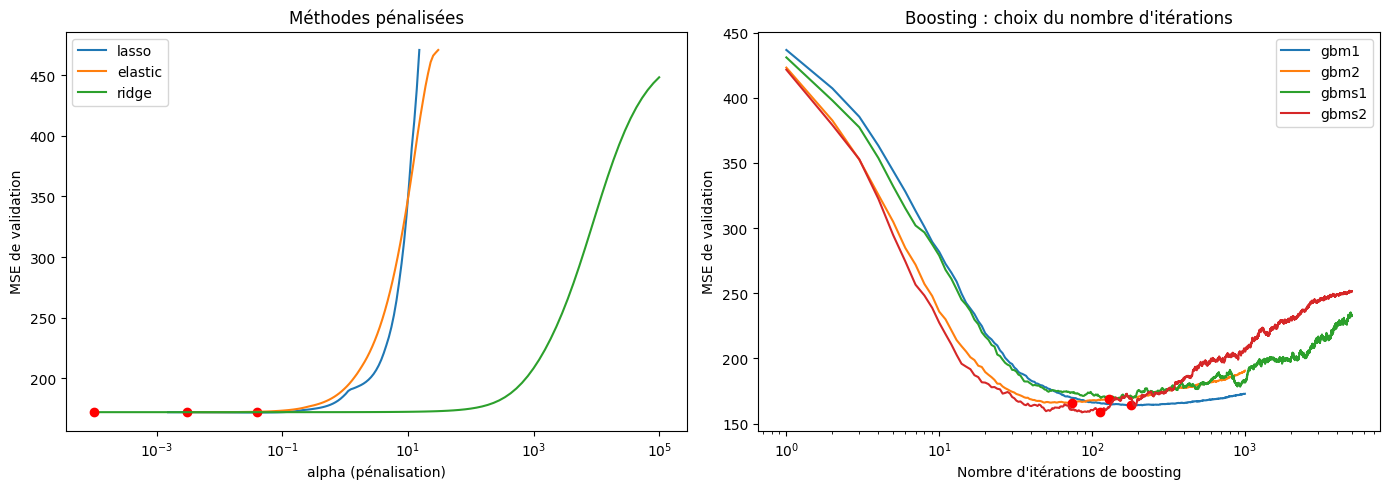

In [6]:
display(pd.Series(hyper, name="valeur retenue").to_frame().round(4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for nom in ("lasso", "elastic", "ridge"):
    grille_a, err = courbes[nom]
    ax1.plot(grille_a, err, label=nom)
    ax1.plot(grille_a[np.argmin(err)], err.min(), "o", color="red")
ax1.set_xscale("log")
ax1.set_xlabel("alpha (pénalisation)")
ax1.set_ylabel("MSE de validation")
ax1.set_title("Méthodes pénalisées")
ax1.legend()

for nom in configs_gbm:
    it, err = courbes[nom]
    ax2.plot(it, err, label=nom)
    ax2.plot(it[np.argmin(err)], err.min(), "o", color="red")
ax2.set_xscale("log")
ax2.set_xlabel("Nombre d'itérations de boosting")
ax2.set_ylabel("MSE de validation")
ax2.set_title("Boosting : choix du nombre d'itérations")
ax2.legend()

plt.tight_layout()
plt.savefig(DOSSIER_SORTIE + "resultats_reg_split_validation.png", dpi=150)
plt.show()

## 5. Export des fichiers et synthèse
`PREV_test.csv` a le même format que `PREV_complet.csv` (colonnes `bloc`, `Y`, puis une colonne par méthode) : il peut être lu par `03_analyseReg_complet.ipynb` (voir `FICHIER_PREV`).

In [7]:
PREV_test = pd.DataFrame({"bloc": "test", "Y": Y_test, **{m: pred_test[m] for m in methodes}}, index=don.index[idx_test])
PREV_test.to_csv(DOSSIER_SORTIE + "PREV_test.csv", index=False)
metriques.round(4).to_csv(DOSSIER_SORTIE + "metriques_reg_split.csv")
pd.Series(hyper, name="valeur retenue").to_csv(DOSSIER_SORTIE + "hyperparametres_reg_split.csv")

meilleur = metriques.index[0]
print(f"Espace {ESPACE} : apprentissage {len(idx_app)} / validation {len(idx_val)} / test {len(idx_test)}")
print(f"Meilleure méthode (MSE test) : {meilleur} (MSE = {metriques.loc[meilleur, 'MSE_test']:.2f}, "
      f"IC95 [{metriques.loc[meilleur, 'IC95_bas']:.1f} ; {metriques.loc[meilleur, 'IC95_haut']:.1f}])")
print(f"MCO : MSE test = {metriques.loc['MCO', 'MSE_test']:.2f} -> gain de {-metriques.loc[meilleur, 'Gain_vs_MCO_%']:.1f} % avec {meilleur}")
print("Top 3 :", ", ".join(f"{m} ({metriques.loc[m, 'MSE_test']:.2f})" for m in metriques.index[:3]))
print("\nFichiers écrits : PREV_test.csv, metriques_reg_split.csv, hyperparametres_reg_split.csv, "
      "resultats_reg_split_mse_residus.png, resultats_reg_split_validation.png")

Espace X : apprentissage 819 / validation 273 / test 274
Meilleure méthode (MSE test) : gbm2 (MSE = 147.17, IC95 [120.5 ; 177.8])
MCO : MSE test = 178.97 -> gain de 17.8 % avec gbm2
Top 3 : gbm2 (147.17), gbms1 (150.38), gbm1 (151.81)

Fichiers écrits : PREV_test.csv, metriques_reg_split.csv, hyperparametres_reg_split.csv, resultats_reg_split_mse_residus.png, resultats_reg_split_validation.png
